# Four-week product sales forecasts

## Context & methods
Train earlier, select on four validation weeks, then evaluate the selected model on four untouched weeks. The top 60 products are chosen before validation. Forecasts use only information available at one origin.

### Key assumptions
Missing product-weeks mean zero observed purchases, not proven zero demand. Forecasts are point estimates; uncertainty has not been calibrated. This initial experiment uses one validation origin and one test origin.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd() if (Path.cwd() / 'artifacts').exists() else Path.cwd().parent
artifacts = root / 'artifacts'
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## Data

In [2]:
metrics = json.loads((artifacts/'forecast_metrics.json').read_text())
print('Selected:', metrics['selected_model'])
print('Validation starts:', metrics['validation_start'])
print('Test starts:', metrics['test_start'])
pd.DataFrame(metrics['validation']).T

Selected: boosted
Validation starts: 2011-10-10
Test starts: 2011-11-07
Out[0]: 
           mae_units   wape_pct convergence_warning
boosted   133.338754  51.540185               False
neural    153.243185  59.233958               False
baseline  146.408333  56.592044                 NaN


## Results

,mae_units,wape_pct
selected,165.706591,42.872709
baseline,176.229167,45.595179


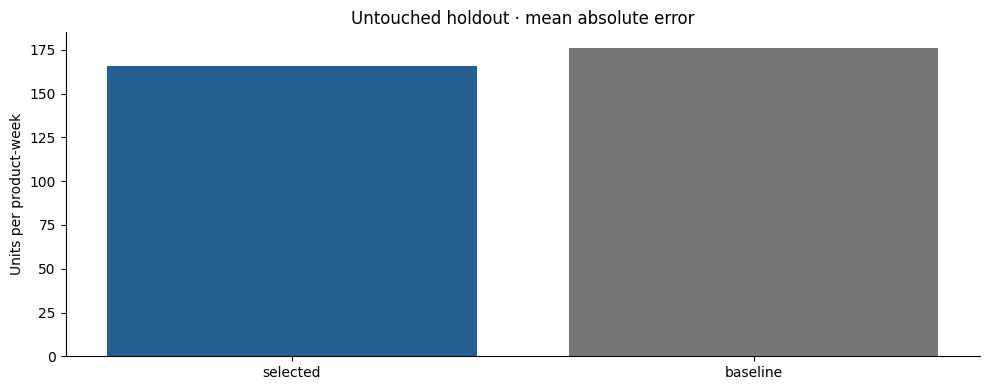

In [3]:
test = pd.DataFrame(metrics['test']).T
display(test)
fig, ax = plt.subplots()
ax.bar(test.index, test.mae_units, color=['#255f92','#777777'])
ax.set(title='Untouched holdout · mean absolute error', ylabel='Units per product-week')
fig.tight_layout()
plt.show()

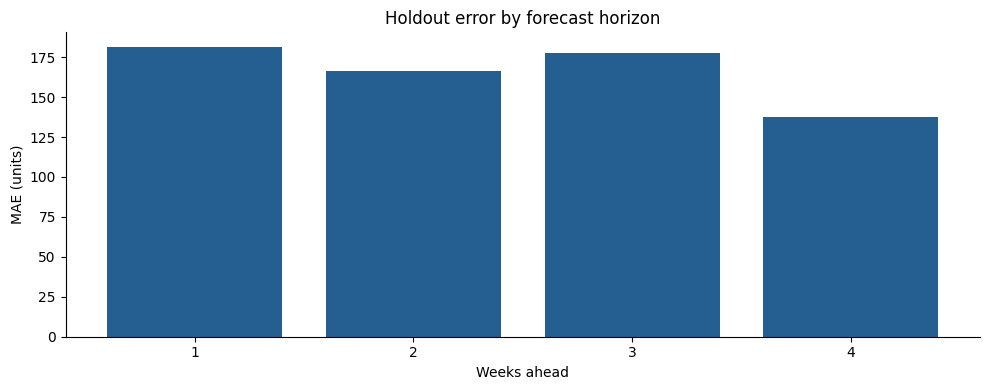

In [4]:
predictions = pd.read_csv(artifacts/'forecast_test.csv', dtype={'product_id': str})
by_horizon = predictions.assign(error=lambda x: abs(x.actual-x.prediction)).groupby('horizon').error.mean()
fig, ax = plt.subplots()
ax.bar(by_horizon.index, by_horizon.values, color='#255f92')
ax.set(title='Holdout error by forecast horizon', xlabel='Weeks ahead', ylabel='MAE (units)')
ax.set_xticks([1,2,3,4])
fig.tight_layout()
plt.show()

## Takeaways
Compare validation and holdout tables before drawing a model-quality conclusion. The selected model is refitted after testing for the final historical forward projection. Those projections are not predictions for the present day. Rolling backtests and error concentration by product remain next steps.